# Time on: which teams finish quarters best?

An AFL quarter is 20 minutes plus **time on**: stoppage time that builds up during
the quarter and is played after the 20-minute mark. AFL Tables' scoring
progression gives every score's time within its quarter and each quarter's
actual length. So each score can be labelled **regular time** (the first 20
minutes) or **time on** (after 20:00), and scoring can be compared **per minute**.

**Question:** which teams do relatively better or worse in time on than in
regular time?

**Data:** every 2026 match page on AFL Tables (home-and-away and finals),
parsed by `src/afl/scoring.py`. Each match's summed points are checked against
its scoreboard.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import bootstrap
from afl.draft_charts import BLUE, BLUE_BAND, GREY, INK, ORANGE, TITLE, apply_style
from afl.scoring import season_scoring

YEAR = 2026
REGULAR_SECONDS = 20 * 60
N_BOOT = 2000
pd.set_option("display.width", 200)
apply_style()

events, quarters = season_scoring(YEAR)
print(f"{quarters['match'].nunique()} matches, {len(events)} scoring events")
print(f"Matches whose summed points match the scoreboard: "
      f"{quarters.drop_duplicates('match')['valid'].sum()} of {quarters['match'].nunique()}")
print("Rounds:", quarters.drop_duplicates("match")["round"].value_counts().sort_index().to_dict())

218 matches, 10722 scoring events
Matches whose summed points match the scoreboard: 218 of 218
Rounds: {'1': 5, '10': 9, '11': 9, '12': 9, '13': 7, '14': 8, '15': 7, '16': 7, '17': 7, '18': 9, '19': 9, '2': 9, '20': 9, '21': 9, '22': 9, '23': 9, '24': 9, '25': 9, '3': 7, '4': 7, '5': 8, '6': 9, '7': 9, '8': 9, '9': 9, 'Elimination Final': 2, 'Grand Final': 1, 'Preliminary Final': 2, 'Qualifying Final': 2, 'Semi Final': 2, 'Wildcard Final': 2}


## 1. How long is time on?

Regular time is always 20 minutes. Time on is whatever comes after.

In [2]:
quarters["time_on_minutes"] = (quarters["length_seconds"] - REGULAR_SECONDS).clip(lower=0) / 60
quarters["regular_minutes"] = quarters["length_seconds"].clip(upper=REGULAR_SECONDS) / 60
print(f"Quarters shorter than 20 minutes: {(quarters['length_seconds'] < REGULAR_SECONDS).sum()}")
quarters.groupby("quarter")["time_on_minutes"].describe()[["mean", "min", "50%", "max"]].round(1)

Quarters shorter than 20 minutes: 0


,mean,min,50%,max
quarter,,,,
1,11.1,6.4,10.8,18.4
2,11.0,5.0,11.0,18.0
3,11.3,5.2,11.1,21.0
4,11.3,2.9,11.1,22.2


## 2. League-wide: is scoring faster in time on?

Points scored by both teams per 10 minutes, in regular time and in time on, for
each quarter.

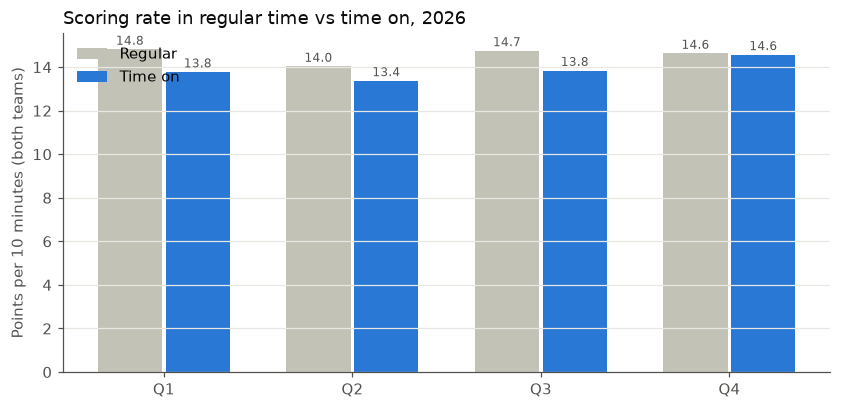

period,Regular,Time on
quarter,,
1,14.81,13.78
2,14.03,13.37
3,14.75,13.84
4,14.63,14.57


In [3]:
events["period"] = np.where(events["seconds"] >= REGULAR_SECONDS, "Time on", "Regular")

rows = []
for q in [1, 2, 3, 4]:
    qe, qq = events[events["quarter"] == q], quarters[quarters["quarter"] == q]
    for period, minutes in [("Regular", qq["regular_minutes"].sum()), ("Time on", qq["time_on_minutes"].sum())]:
        points = qe.loc[qe["period"] == period, "points"].sum()
        rows.append({"quarter": q, "period": period, "minutes": minutes, "points": points,
                     "points per 10 min": points / minutes * 10})
league = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for offset, (period, colour) in zip([-0.18, 0.18], [("Regular", GREY), ("Time on", BLUE)]):
    part = league[league["period"] == period]
    ax.bar(x + offset, part["points per 10 min"], width=0.34, color=colour, label=period)
    for xi, value in zip(x + offset, part["points per 10 min"]):
        ax.annotate(f"{value:.1f}", (xi, value), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
ax.set_xticks(x, ["Q1", "Q2", "Q3", "Q4"])
ax.set_ylabel("Points per 10 minutes (both teams)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Scoring rate in regular time vs time on, {YEAR}", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper left")
plt.show()
league.pivot(index="quarter", columns="period", values="points per 10 min").round(2)

## 3. By team: who does relatively better in time on?

For each team and each match: points **for** and **against** in regular time
and in time on, and the minutes played in each.

- **Margin per 10 minutes** = (points for − points against) ÷ minutes × 10,
  for regular time and for time on separately.
- **Time-on edge** = time-on margin minus regular-time margin.
  - Positive: the team does *relatively better* in time on than its overall
    strength suggests.
  - Negative: it fades in time on.
- **Intervals:** 95% bootstrap intervals from resampling the team's matches
  (2,000 resamples).

Strong teams will be positive in both periods. The edge removes that, so it
shows what's specific to time on.

In [4]:
# One row per team per match: points for/against in each period, and minutes
match_minutes = quarters.groupby("match")[["regular_minutes", "time_on_minutes"]].sum()
teams = pd.concat([
    quarters.drop_duplicates("match")[["match", "home", "away"]].rename(columns={"home": "team", "away": "opponent"}),
    quarters.drop_duplicates("match")[["match", "home", "away"]].rename(columns={"away": "team", "home": "opponent"}),
], ignore_index=True)

scored = events.groupby(["match", "team", "period"])["points"].sum().unstack(fill_value=0)
for side, key in [("for", "team"), ("against", "opponent")]:
    pts = scored.reindex(pd.MultiIndex.from_frame(teams[["match", key]])).fillna(0).to_numpy()
    teams[f"regular_{side}"] = pts[:, 0]
    teams[f"time_on_{side}"] = pts[:, 1]
teams = teams.join(match_minutes, on="match")
assert list(scored.columns) == ["Regular", "Time on"]


def margins(d):
    """Regular-time margin, time-on margin and their difference, per 10 minutes."""
    regular = (d["regular_for"].sum() - d["regular_against"].sum()) / d["regular_minutes"].sum() * 10
    time_on = (d["time_on_for"].sum() - d["time_on_against"].sum()) / d["time_on_minutes"].sum() * 10
    return regular, time_on, time_on - regular


rows = []
for team, d in teams.groupby("team"):
    regular, time_on, edge = margins(d)
    est, low, high = bootstrap(d, lambda x: margins(x)[2], n=N_BOOT)
    rows.append({"team": team, "matches": len(d), "time-on minutes": d["time_on_minutes"].sum(),
                 "regular margin /10 min": regular, "time-on margin /10 min": time_on,
                 "time-on edge": edge, "low": low, "high": high})
by_team = pd.DataFrame(rows).set_index("team").sort_values("time-on edge", ascending=False)
by_team.round(2)

,matches,time-on minutes,regular margin /10 min,time-on margin /10 min,time-on edge,low,high
team,,,,,,,
North Melbourne,23,1009.22,-1.76,0.80,2.56,0.71,4.46
Collingwood,24,1055.13,-0.51,1.35,1.86,-0.45,4.05
Greater Western Sydney,23,1067.92,-0.71,1.02,1.73,-0.45,3.92
Richmond,23,977.57,-3.50,-2.52,0.98,-1.07,3.16
Gold Coast,23,1021.27,-0.75,0.21,0.96,-1.35,3.14
Sydney,25,1206.08,2.05,2.52,0.47,-1.77,2.71
Melbourne,24,1091.38,0.46,0.87,0.41,-1.91,2.70
Port Adelaide,23,999.57,-0.92,-0.75,0.17,-2.20,2.44
Brisbane Lions,27,1273.37,1.45,1.16,-0.29,-2.27,1.82


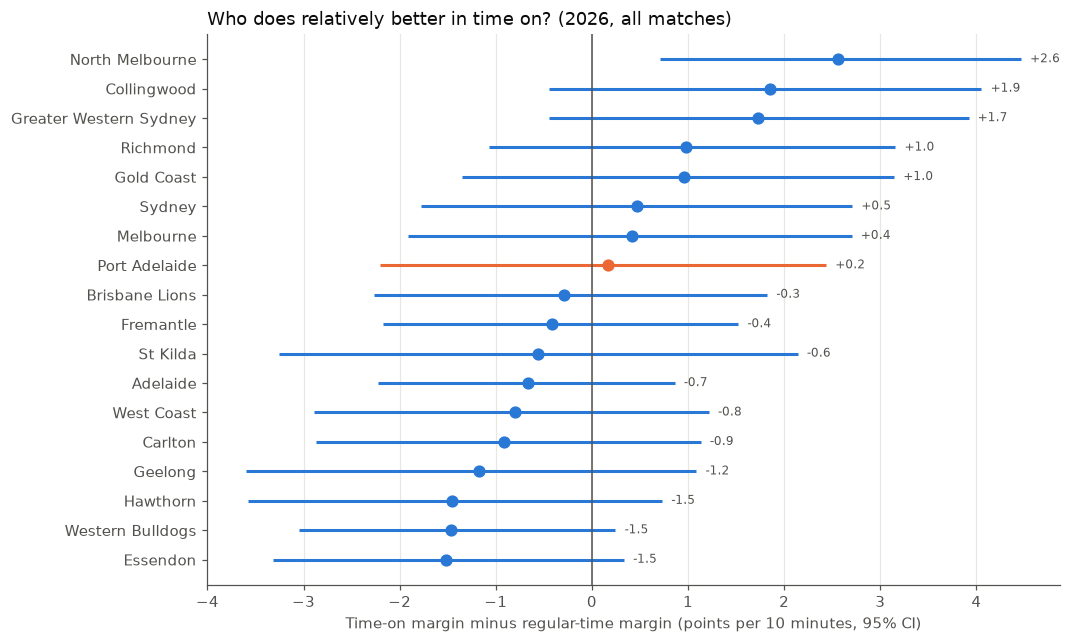

In [5]:
plot = by_team.sort_values("time-on edge")
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(plot))
for yi, (team, row) in zip(y, plot.iterrows()):
    colour = ORANGE if team == "Port Adelaide" else BLUE
    ax.errorbar(row["time-on edge"], yi, xerr=[[row["time-on edge"] - row["low"]], [row["high"] - row["time-on edge"]]],
                fmt="o", color=colour, markersize=7, capsize=0, elinewidth=2)
    ax.annotate(f"{row['time-on edge']:+.1f}", (row["high"], yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, plot.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Time-on margin minus regular-time margin (points per 10 minutes, 95% CI)")
ax.set_title(f"Who does relatively better in time on? ({YEAR}, all matches)", loc="left", color=TITLE)
plt.show()

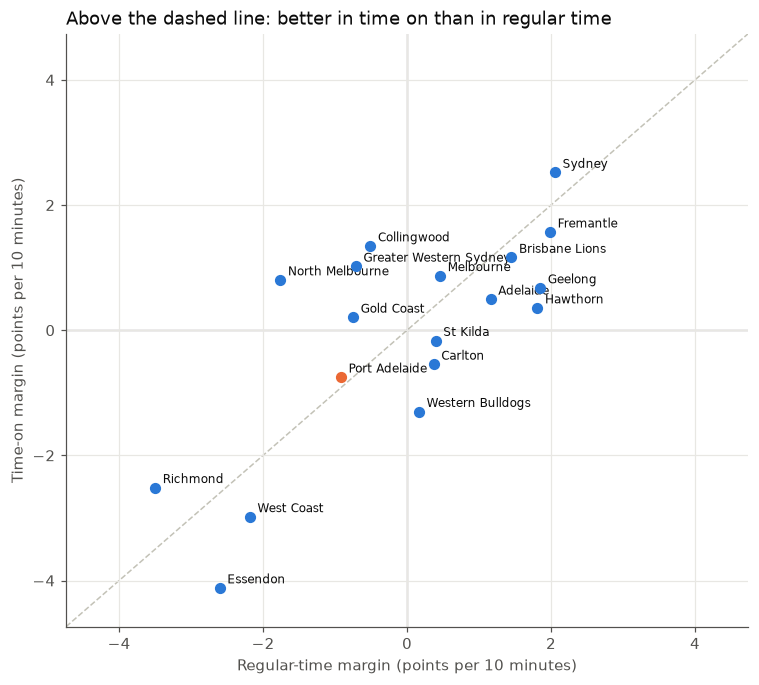

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
lim = max(by_team[["regular margin /10 min", "time-on margin /10 min"]].abs().max()) * 1.15
ax.plot([-lim, lim], [-lim, lim], color=GREY, linewidth=1, linestyle="--", zorder=0)
ax.axhline(0, color=INK, linewidth=0.8, zorder=0)
ax.axvline(0, color=INK, linewidth=0.8, zorder=0)
for team, row in by_team.iterrows():
    colour = ORANGE if team == "Port Adelaide" else BLUE
    ax.scatter(row["regular margin /10 min"], row["time-on margin /10 min"], s=40, color=colour, zorder=3)
    ax.annotate(team, (row["regular margin /10 min"], row["time-on margin /10 min"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=TITLE)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Regular-time margin (points per 10 minutes)")
ax.set_ylabel("Time-on margin (points per 10 minutes)")
ax.set_title("Above the dashed line: better in time on than in regular time", loc="left", color=TITLE)
plt.show()

## 4. Check: quarters 1–3 only

In final-quarter time on, the result is often already decided, and the leading
team may simply play it safe. Leaving out the fourth quarter checks that the
team pattern isn't just about how teams protect a lead.

In [7]:
q13 = quarters[quarters["quarter"] <= 3]
ev13 = events[events["quarter"] <= 3]
minutes13 = q13.groupby("match")[["regular_minutes", "time_on_minutes"]].sum()
scored13 = ev13.groupby(["match", "team", "period"])["points"].sum().unstack(fill_value=0)
teams13 = teams[["match", "team", "opponent"]].copy()
for side, key in [("for", "team"), ("against", "opponent")]:
    pts = scored13.reindex(pd.MultiIndex.from_frame(teams13[["match", key]])).fillna(0).to_numpy()
    teams13[f"regular_{side}"] = pts[:, 0]
    teams13[f"time_on_{side}"] = pts[:, 1]
teams13 = teams13.join(minutes13, on="match")

compare = pd.DataFrame({
    "edge, all quarters": by_team["time-on edge"],
    "edge, Q1-Q3 only": {team: margins(d)[2] for team, d in teams13.groupby("team")},
}).sort_values("edge, all quarters", ascending=False)
print(f"Correlation between the two: {compare.corr().iloc[0, 1]:.2f}")
compare.round(2)

Correlation between the two: 0.92


,"edge, all quarters","edge, Q1-Q3 only"
North Melbourne,2.56,1.97
Collingwood,1.86,2.80
Greater Western Sydney,1.73,1.77
Richmond,0.98,1.36
Gold Coast,0.96,0.37
Sydney,0.47,0.64
Melbourne,0.41,0.95
Port Adelaide,0.17,-0.48
Brisbane Lions,-0.29,-1.45
Fremantle,-0.42,-0.44


# Results

## Data

- **All 218 matches of 2026** (207 home-and-away games and 11 finals, including
  the new Wildcard Finals) were parsed. **Every match's summed points equal its
  scoreboard.**
- **10,722 scoring events.** Every quarter ran longer than 20 minutes.

## League-wide

- **Time on averages about 11 minutes a quarter**, so a quarter typically runs
  about 31 minutes in total. That ranges from under 3 minutes to over 22.
- **Scoring is slightly slower in time on** in the first three quarters: about
  13.4–13.8 points per 10 minutes, against 14.0–14.8 in regular time, roughly 6%
  less. In the final quarter there's no difference (14.6 vs 14.6).

## By team

- **No team is clearly different in time on in 2026.**
  - Only North Melbourne's edge has an interval that excludes 0 (+2.6 points
    per 10 minutes, CI +0.7 to +4.5).
  - With 18 teams, about 1 would do that by chance alone.
  - Collingwood (+1.9) and GWS (+1.7) lean positive. Essendon, the Western
    Bulldogs and Hawthorn (about −1.5) lean negative. All of their intervals
    include 0.
- **Port Adelaide: +0.2 (CI −2.2 to +2.4).** No difference between its time-on
  and regular-time performance.
- **It isn't about final-quarter game state.** Leaving out the fourth quarter
  gives almost the same team pattern (correlation 0.92).
- **Some of the pattern is just compression.** Time-on margins track
  regular-time margins (correlation 0.74), but they're about **75% as large**.
  So weaker teams tend to show positive edges and stronger teams negative ones
  (correlation of edge with team strength: −0.34). North Melbourne's top ranking
  is partly this effect: a weak team whose margin shrinks towards zero in time on.

## What this adds up to

On one season, **time on is a little lower-scoring than regular time, and margins
shrink in it**, but there's no convincing evidence that particular teams are
built to win (or lose) time on. Any real team differences are smaller than one
season of data can detect.

## Possible next steps

1. **Add 2025** (about 207 more match pages). That roughly doubles each team's
   time-on minutes and would show whether the leaning teams (North Melbourne,
   Collingwood, GWS; Essendon, Bulldogs, Hawthorn) stay that way.
2. **Allow for the compression:** compare each team's time-on margin with what's
   *expected* from its regular-time margin (about 0.75 ×), instead of with the
   regular-time margin itself.
3. **Game state:** in time on, do leading teams score less and trailing teams
   more? That would explain the compression directly.